![The blog’s ninja owl investigating feature importance](https://howtolearnmachinelearning.com/wp-content/uploads/2026/11/permutation-importance-anime-owl.png)

# Permutation feature importance in Python

**Hey friends!** A teammate has ranked four sensors by shuffling their readings one column at a time. They want to monitor only the sensor at the top. There’s a catch. Two sensors report the same measurement under different names. Could the individual ranking hide how much your model depends on that measurement?

**Your brief** is to identify the duplicate pair and test what happens when their shared measurement is scrambled. Make a prediction before each experiment. Use the evidence to write a monitoring recommendation. Allow about 15 minutes. Run the cells in order with Shift+Enter. The notebook generates its own data and runs on a CPU.

[Read the companion article](https://howtolearnmachinelearning.com/articles/permutation-feature-importance-python/)

## 1. Check that the model has learned something

The setup reproduces the article’s synthetic regression problem. The four columns have neutral labels for the investigation. Fit ridge regression once on 1,800 rows. The next 600 rows supply the validation evidence. Keep the remaining 600 test rows in reserve.

Compare the model with a simple forecast that always predicts the training mean. Which has the smaller mean squared error (MSE)?

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(42)
primary, secondary, noise = rng.normal(size=(3, 3000))
features = np.column_stack([secondary, primary, noise, primary.copy()])
target = 3 * primary + 2 * secondary + rng.normal(size=3000)
labels = ["A", "B", "C", "D"]
X_train, X_rest, y_train, y_rest = train_test_split(
    features, target, test_size=0.4, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_rest, y_rest, test_size=0.5, random_state=42)
model = Ridge(alpha=1.0).fit(X_train, y_train)
reference_mse = mean_squared_error(y_val, model.predict(X_val))
constant_mse = mean_squared_error(y_val, np.full(len(y_val), y_train.mean()))
print(f"Training-mean forecast: {constant_mse:.3f} MSE")
print(f"Ridge forecast:         {reference_mse:.3f} MSE")

Training-mean forecast: 13.568 MSE
Ridge forecast:         1.073 MSE


## 2. Pick a suspect

Look across the six rows below. Which two sensors seem to agree? Which feature do you expect to cause the largest error increase when shuffled alone? Write down a reason. It's fine to discover that your guess was wrong.

In [2]:
print("       A        B        C        D")
for row in X_val[:6]:
    print(" ".join(f"{v:8.3f}" for v in row))

       A        B        C        D
  -0.071    1.382   -0.423    1.382
  -0.188   -0.965    0.071   -0.965
   0.040   -0.888    0.753   -0.888
   0.876   -0.024   -0.205   -0.024
   0.107   -1.831    1.538   -1.831
   1.176   -0.183    0.499   -0.183


## 3. Run the single-column experiment

Choose a sensor and explain your prediction in the cell. The experiment shuffles one feature at a time across validation rows, then measures the error of the same fitted model. A larger increase means the disruption hurt its predictions more. With negative MSE scoring in scikit-learn, the reported score drop equals **shuffled MSE minus original MSE**.

In [3]:
single = permutation_importance(
    model, X_val, y_val, scoring="neg_mean_squared_error",
    n_repeats=30, random_state=42, n_jobs=1)

def show_ranking(guess, reason):
    if guess not in labels or not isinstance(reason, str) or not reason.strip():
        print("Pick A, B, C, or D and write down why. Then rerun this cell.")
        return
    winner = labels[int(np.argmax(single.importances_mean))]
    print(f"Your prediction: {guess}. Largest measured individual increase: {winner}.")
    fig, ax = plt.subplots(figsize=(7, 3.6), layout="constrained")
    ax.barh(labels, single.importances_mean, xerr=single.importances_std,
            color=["#b72364" if s == guess else "#22594f" for s in labels], capsize=4)
    ax.invert_yaxis()
    ax.set(xlabel="Increase in validation MSE", title="One sensor shuffled at a time")
    plt.show()
    for sensor, delta in zip(labels, single.importances_mean):
        print(f"{sensor}: {delta:.3f}")

single_guess = None  # "A", "B", "C", or "D"
my_reason = ""       # What did you notice in the data?
show_ranking(single_guess, my_reason)

Pick A, B, C, or D and write down why. Then rerun this cell.


The error bars show one standard deviation across 30 random shuffles on these same cases. They describe sensitivity to shuffle order. To study uncertainty across new datasets or fitted models, you would need a different experiment.

## 4. Design a fair test of the pair

Imagine two rows with matching readings `(4, 4)` and `(9, 9)`. Moving the pair together can swap their rows while preserving that agreement. Separate shuffles can create `(4, 9)`, a combination absent from the original data.

Pick two sensors. Choose **shared** or **independent** row orders. Before running, predict whether the pair’s mean error increase will be **above** or **below** the largest single-column increase. You can retry with another pair or design. Use the feedback to change one thing at a time.

In [4]:
def investigate(pair, shuffle_mode, prediction):
    if not isinstance(pair, (tuple, list)) or len(pair) != 2 or any(v not in labels for v in pair) or pair[0] == pair[1]:
        print("Choose two different sensors, for example ['A', 'C'].")
        return False
    if shuffle_mode not in ("shared", "independent") or prediction not in ("above", "below"):
        print("Choose a shuffle design and predict above or below before measuring.")
        return False
    cols = [labels.index(sensor) for sensor in pair]
    duplicate = np.array_equal(X_val[:, cols[0]], X_val[:, cols[1]])
    generator = np.random.default_rng(42)
    increases = []
    for repeat in range(30):
        shuffled = X_val.copy()
        order = generator.permutation(len(X_val))
        second_order = order if shuffle_mode == "shared" else generator.permutation(len(X_val))
        shuffled[:, cols[0]] = X_val[order, cols[0]]
        shuffled[:, cols[1]] = X_val[second_order, cols[1]]
        increases.append(mean_squared_error(y_val, model.predict(shuffled)) - reference_mse)
    mean_increase = np.mean(increases)
    strongest = single.importances_mean.max()
    observed = "above" if mean_increase > strongest else "below" if mean_increase < strongest else "equal"
    print(f"Paired shuffle: {mean_increase:.3f} MSE increase (SD {np.std(increases):.3f}).")
    print(f"Strongest single shuffle: {strongest:.3f}. Your prediction: {prediction}.")
    if not duplicate:
        print("Large error alone cannot identify duplicate readings. Check which columns agree on every row.")
    elif shuffle_mode != "shared":
        print("You found the duplicate columns. Which design preserves their agreement after shuffling?")
    elif prediction != observed:
        print("The design preserves the pair. Compare the two error increases and revise your prediction.")
    else:
        print("You found the pair and preserved its internal relationship. Record both error increases.")
        return True
    return False

In [5]:
sensor_pair = []         # Enter two sensor labels
shuffle_design = None    # "shared" or "independent"
expected_change = None   # "above" or "below"
solved = investigate(sensor_pair, shuffle_design, expected_change)

Choose two different sensors, for example ['A', 'C'].


## 5. Decide what to monitor

**Decision note.** Complete this sentence before reading on: “I would monitor ___ because scrambling it increased validation MSE by ___. Looking only at the single-column ranking would have led me to ___.”

If a teammate wants to delete one copy to simplify the pipeline, what new experiment would answer whether the *retrained* model still performs well?

## Worked answers

**The strongest individual feature is A**, the secondary signal. Shuffling it increases validation MSE by about **7.084**. B and D each increase it by about **4.531**. C is synthetic noise and its measured increase rounds to zero.

**The hidden pair is B and D.** They contain identical primary readings. Ridge split the fitted weight between them. Scrambling either copy individually leaves the other aligned with its original row and creates mismatched pairs. Moving both together preserves their agreement while breaking their alignment with the target. The joint increase is **18.299**, above the largest individual increase. Squared error depends on the combined prediction change, so adding the two individual increases gives a different answer.

**A defensible recommendation** is to monitor the shared measurement feeding B and D, check that both copies agree, and also monitor A. The evidence describes this fitted model on these validation cases. A causal effect would require further assumptions or a suitable causal study. To decide about dropping a copy, refit with one copy removed, compare validation performance under the same split, and evaluate the chosen pipeline on independent test data.

[Companion article](https://howtolearnmachinelearning.com/articles/permutation-feature-importance-python/) · [Model evaluation guide](https://howtolearnmachinelearning.com/articles/evaluating-machine-learning-models/) · [Free 90-Day Machine Learning Roadmap](https://how-to-learn-machine-learning.kit.com/7a25f667cb)

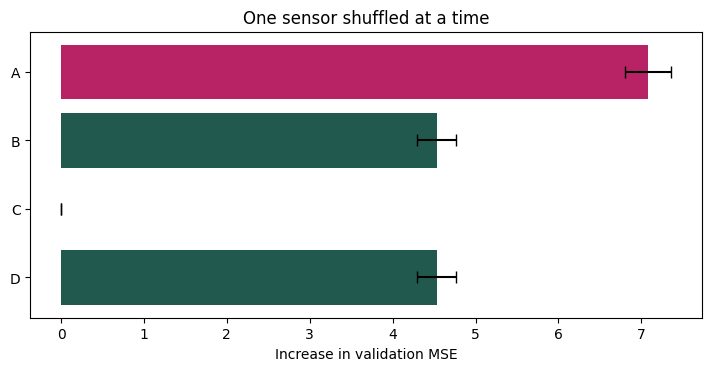

Your prediction: A. Largest measured individual increase: A.
A: 7.084
B: 4.531
C: 0.000
D: 4.531
Paired shuffle: 18.299 MSE increase (SD 0.825).
Strongest single shuffle: 7.084. Your prediction: above.
You found the pair and preserved its internal relationship. Record both error increases.


In [6]:
# Reproduce the solution and its chart after completing your decision note.
show_ranking("A", "Compare the individual ranking with the joint experiment.")
investigate(["B", "D"], "shared", "above")